# Notebook 08: Anomaly Detection (Store CA_1)
## Step 1: Import Libraries and Verify Uploaded Files

### What we are doing in this cell
We are importing the Python libraries needed for data handling, visualization, and machine learning. We are also setting our file paths and checking that all four uploaded files are present in Google Colab.

### Why we need this step
Keeping all imports and file paths in the very first cell makes the notebook organized and easy to manage. Verifying the files right away ensures we do not run into missing-file errors later.

### What problem this step solves
It prevents `FileNotFoundError` crashes and sets a fixed random seed (`RANDOM_STATE = 42`) so our machine learning results stay consistent every time we run the notebook.

### What output we should expect
A confirmation message showing `[OK]` and the file size (in MB) for each of the four uploaded files.

In [ ]:
# Standard Python libraries for file handling and JSON
import os
import json
import warnings

# Libraries for data manipulation and math
import numpy as np
import pandas as pd

# Library for loading and saving machine learning models
import joblib

# Libraries for creating charts and plots
import matplotlib.pyplot as plt
import seaborn as sns

# Ignore minor warning messages to keep output clean
warnings.filterwarnings("ignore")

# Set a fixed random seed for reproducible results
RANDOM_STATE = 42

# Define file paths for the manually uploaded files in Google Colab
MODEL_PATH = "/content/lightgbm_h7.joblib"
TRAIN_PATH = "/content/ca1_h7_train.parquet"
VAL_PATH = "/content/ca1_h7_val.parquet"
FEATURES_PATH = "/content/feature_lists.json"

# Put all paths in a dictionary so we can check them easily
files_to_check = {
    "H7 LightGBM Model": MODEL_PATH,
    "Training Data": TRAIN_PATH,
    "Validation Data": VAL_PATH,
    "Feature Lists JSON": FEATURES_PATH
}

print("Checking uploaded files in Google Colab...\n")

all_files_found = True

for label, path in files_to_check.items():
    if os.path.exists(path):
        # Get file size in Megabytes (MB)
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"[OK] {label}: {path} ({size_mb:.2f} MB)")
    else:
        print(f"[MISSING] {label}: {path} NOT FOUND!")
        all_files_found = False

print("\nStatus:", "All files are ready!" if all_files_found else "Some files are missing. Please check the file names.")

Checking uploaded files in Google Colab...

[OK] H7 LightGBM Model: /content/lightgbm_h7.joblib (1.74 MB)
[OK] Training Data: /content/ca1_h7_train.parquet (14.83 MB)
[OK] Validation Data: /content/ca1_h7_val.parquet (0.22 MB)
[OK] Feature Lists JSON: /content/feature_lists.json (0.06 MB)

Status: All files are ready!


## Step 2: Load Model, Feature Lists, and Datasets & Inspect Data

### What we are doing in this cell
We are loading our existing H7 LightGBM model, the `feature_lists.json` file, and both the training and validation datasets into memory. Then, we will inspect their shapes, column names, date ranges, and missing values.

### Why we need this step
Before running predictions or building anomaly detection, we must confirm that the datasets loaded properly, cover the expected date ranges, and contain all the columns required by the H7 model.

### What problem this step solves
It prevents hidden data issues—such as missing features, unexpected `NaN` values, or data leakage (e.g., validation dates accidentally appearing in training data)—from breaking our pipeline later.

### What output we should expect
The model type, the keys inside `feature_lists.json`, the row/column counts (shapes) of both datasets, their exact date ranges, a list of all columns, and a summary of any missing values.

In [ ]:
# 1. Load the trained H7 LightGBM model
model_h7 = joblib.load(MODEL_PATH)
print("Loaded Model Type:", type(model_h7))

# 2. Load the feature_lists.json file
with open(FEATURES_PATH, "r") as file:
    feature_lists = json.load(file)

print("\nContents / Keys in feature_lists.json:")
if isinstance(feature_lists, dict):
    for key, value in feature_lists.items():
        if isinstance(value, list):
            print(f" - {key}: {len(value)} features")
        else:
            print(f" - {key}: {value}")
else:
    print(f" - Total features in list: {len(feature_lists)}")

# 3. Load Training and Validation datasets
print("\nLoading parquet datasets (this may take a few seconds)...")
train_df = pd.read_parquet(TRAIN_PATH)
val_df = pd.read_parquet(VAL_PATH)

# 4. Inspect dataset shapes (rows, columns)
print(f"\nTraining Data Shape:   {train_df.shape[0]:,} rows, {train_df.shape[1]} columns")
print(f"Validation Data Shape: {val_df.shape[0]:,} rows, {val_df.shape[1]} columns")

# 5. Inspect column names
print("\nColumns in Validation Data:")
print(list(val_df.columns))

# 6. Check date ranges (if a 'date' column exists)
if "date" in train_df.columns and "date" in val_df.columns:
    print(f"\nTraining Date Range:   {train_df['date'].min()} to {train_df['date'].max()}")
    print(f"Validation Date Range: {val_df['date'].min()} to {val_df['date'].max()}")
else:
    print("\nNote: No column named exactly 'date' found. Please check the column list above.")

# 7. Check for missing values in both datasets
train_missing = train_df.isnull().sum()
val_missing = val_df.isnull().sum()

train_missing = train_missing[train_missing > 0]
val_missing = val_missing[val_missing > 0]

print("\nMissing Values in Training Data:")
print(train_missing if len(train_missing) > 0 else "None (0 missing values)")

print("\nMissing Values in Validation Data:")
print(val_missing if len(val_missing) > 0 else "None (0 missing values)")

Loaded Model Type: <class 'lightgbm.sklearn.LGBMRegressor'>

Contents / Keys in feature_lists.json:
 - features_7: 27 features
 - features_28: 27 features
 - item_categories: 3049 features

Loading parquet datasets (this may take a few seconds)...

Training Data Shape:   4,552,041 rows, 26 columns
Validation Data Shape: 85,372 rows, 26 columns

Columns in Validation Data:
['item_id', 'store_id', 'date', 'sales', 'lag_7', 'rolling_mean_7', 'wday', 'month', 'year', 'is_weekend', 'snap', 'has_event', 'sell_price', 'price_change', 'ev_Cultural', 'ev_National', 'ev_Religious', 'ev_Sporting', 'ev_None', 'dept_FOODS_1', 'dept_FOODS_2', 'dept_FOODS_3', 'dept_HOBBIES_1', 'dept_HOBBIES_2', 'dept_HOUSEHOLD_1', 'dept_HOUSEHOLD_2']

Training Date Range:   2011-02-09 00:00:00 to 2016-03-27 00:00:00
Validation Date Range: 2016-03-28 00:00:00 to 2016-04-24 00:00:00

Missing Values in Training Data:
None (0 missing values)

Missing Values in Validation Data:
None (0 missing values)


## Step 3: Verify Required Model Features

### What we are doing in this cell
We are inspecting the exact list of features inside `features_7` and checking what features our loaded `model_h7` expects. Then we will compare them against the columns available in `val_df`.

### Why we need this step
Our validation dataset has 26 columns, while `features_7` lists 27 features. Before running predictions, we must check if any required feature is missing or needs a specific data type (such as converting `item_id` to a categorical column).

### What problem this step solves
It prevents `KeyError` or feature-mismatch errors when calling `model_h7.predict()`, and tells us immediately if any column is missing.

### What output we should expect
The exact list of features expected by the model, the list of features in `features_7`, and a clear report showing which columns (if any) are missing from `val_df`.

In [ ]:
# 1. Get the feature list from feature_lists.json
features_7 = feature_lists["features_7"]
print(f"Total features in features_7: {len(features_7)}")
print("features_7 list:")
print(features_7)

# 2. Check the exact feature names saved inside the trained LightGBM model
model_features = list(model_h7.feature_name_)
print(f"\nTotal features expected by model_h7: {len(model_features)}")
print("model_h7 expected features:")
print(model_features)

# 3. Compare model's expected features with columns in val_df
val_columns = list(val_df.columns)
missing_in_val = [col for col in model_features if col not in val_columns]

print("\n--- Feature Verification Report ---")
if len(missing_in_val) == 0:
    print("[OK] All required features are present in val_df!")
else:
    print(f"[WARNING] {len(missing_in_val)} required feature(s) are MISSING from val_df:")
    for col in missing_in_val:
        print(f" - {col}")

# 4. Check the data type of item_id (since item_categories is in JSON)
print(f"\nCurrent dtype of 'item_id' in val_df: {val_df['item_id'].dtype}")

Total features in features_7: 27
features_7 list:
['item_id', 'lag_7', 'rolling_mean_7', 'wday', 'month', 'year', 'is_weekend', 'snap', 'has_event', 'sell_price', 'price_change', 'ev_Cultural', 'ev_National', 'ev_Religious', 'ev_Sporting', 'ev_None', 'dept_FOODS_1', 'dept_FOODS_2', 'dept_FOODS_3', 'dept_HOBBIES_1', 'dept_HOBBIES_2', 'dept_HOUSEHOLD_1', 'dept_HOUSEHOLD_2', 'wday_sin', 'wday_cos', 'month_sin', 'month_cos']

Total features expected by model_h7: 27
model_h7 expected features:
['item_id', 'lag_7', 'rolling_mean_7', 'wday', 'month', 'year', 'is_weekend', 'snap', 'has_event', 'sell_price', 'price_change', 'ev_Cultural', 'ev_National', 'ev_Religious', 'ev_Sporting', 'ev_None', 'dept_FOODS_1', 'dept_FOODS_2', 'dept_FOODS_3', 'dept_HOBBIES_1', 'dept_HOBBIES_2', 'dept_HOUSEHOLD_1', 'dept_HOUSEHOLD_2', 'wday_sin', 'wday_cos', 'month_sin', 'month_cos']

--- Feature Verification Report ---
[WARNING] 4 required feature(s) are MISSING from val_df:
 - wday_sin
 - wday_cos
 - month_sin


## Step 4: Generate Validation Predictions, Residuals, and WAPE

### What we are doing in this cell
First, we recreate the 4 missing cyclical time features (`wday_sin`, `wday_cos`, `month_sin`, `month_cos`) using the existing `wday` and `month` columns. Next, we use our loaded `model_h7` to generate 7-day sales forecasts on the validation dataset, calculate residuals (`actual_sales - forecast_sales`), and compute the validation WAPE.

### Why we need this step
To detect anomalies, we must compare what actually happened (`sales`) against what our model expected to happen (`forecast`). Checking the validation WAPE also confirms that our model is producing the same accuracy we achieved in Notebook 07.

### What problem this step solves
It resolves the 4 missing cyclical features so `model_h7.predict()` runs without errors, ensures no negative sales forecasts exist, and creates the `residual` column needed for anomaly detection.

### What output we should expect
The validation WAPE (percentage), MAE, RMSE, and a preview of the first 5 rows showing `item_id`, `date`, `sales`, `forecast`, and `residual`.

In [ ]:
# 1. Recreate the 4 missing cyclical features from existing 'wday' and 'month' columns
val_df["wday_sin"] = np.sin(2 * np.pi * val_df["wday"] / 7)
val_df["wday_cos"] = np.cos(2 * np.pi * val_df["wday"] / 7)
val_df["month_sin"] = np.sin(2 * np.pi * val_df["month"] / 12)
val_df["month_cos"] = np.cos(2 * np.pi * val_df["month"] / 12)

# 2. Ensure 'item_id' uses the exact category list from feature_lists.json
val_df["item_id"] = pd.Categorical(
    val_df["item_id"],
    categories=feature_lists["item_categories"]
)

# 3. Select the exact 27 features in the exact order expected by model_h7
X_val = val_df[model_features]

# 4. Generate 7-day validation forecasts
print("Generating validation predictions using model_h7...")
raw_predictions = model_h7.predict(X_val)

# Sales cannot be negative, so clip any negative predictions to 0
val_df["forecast"] = np.clip(raw_predictions, 0, None)

# 5. Calculate residual: actual_sales - forecast_sales
val_df["residual"] = val_df["sales"] - val_df["forecast"]

# 6. Calculate validation error metrics (WAPE, MAE, RMSE)
total_abs_error = np.abs(val_df["residual"]).sum()
total_actual_sales = val_df["sales"].sum()

wape = (total_abs_error / total_actual_sales) * 100
mae = np.abs(val_df["residual"]).mean()
rmse = np.sqrt((val_df["residual"] ** 2).mean())

print("\n--- Validation Forecast Performance (H7 LightGBM) ---")
print(f"WAPE: {wape:.2f}%")
print(f"MAE:  {mae:.4f} units")
print(f"RMSE: {rmse:.4f} units")

# 7. Preview the first 5 rows of predictions and residuals
print("\nSample Validation Predictions:")
print(val_df[["item_id", "date", "sales", "forecast", "residual"]].head())

Generating validation predictions using model_h7...

--- Validation Forecast Performance (H7 LightGBM) ---
WAPE: 73.51%
MAE:  1.1017 units
RMSE: 2.1367 units

Sample Validation Predictions:
       item_id       date  sales  forecast  residual
0  FOODS_1_001 2016-03-28      2  0.694105  1.305895
1  FOODS_1_001 2016-03-29      1  0.890745  0.109255
2  FOODS_1_001 2016-03-30      1  0.994175  0.005825
3  FOODS_1_001 2016-03-31      0  0.949817 -0.949817
4  FOODS_1_001 2016-04-01      4  1.103135  2.896865


## Step 5: Rule-Based Anomaly Detection (Validation Data)

### What we are doing in this cell
We are applying a simple, transparent rule-based method to flag unusual sales days in the validation dataset. A day is flagged as an anomaly only if **both** conditions are true:
1. Its absolute residual is greater than **3 times the normal error** (standard deviation of residuals).
2. Its absolute residual is greater than **3 units**.

We also label each flagged anomaly as either a **spike** (actual sales much higher than forecast) or a **drop** (actual sales much lower than forecast).

### Why we need this step
Not every forecast error is an anomaly. Small differences (like selling 2 units instead of 1) happen naturally every day in retail. Combining a statistical threshold (`3x normal error`) with a practical minimum (`> 3 units`) ensures we only alert store managers about truly meaningful surprises.

### What problem this step solves
It filters out everyday retail noise and gives us a clean baseline list of unusual spikes and drops before we introduce machine learning methods like Isolation Forest.

### What output we should expect
The calculated normal error and 3x threshold, the total number (and percentage) of rule-based anomalies, the breakdown of spikes vs. drops, and a preview of the top 5 largest anomalies.

In [ ]:
# 1. Calculate the "normal error" (standard deviation of validation residuals)
normal_error = val_df["residual"].std()

# 2. Define the two rule thresholds
threshold_3x = 3 * normal_error
min_unit_threshold = 3.0

print(f"Normal Error (Residual Std Dev): {normal_error:.4f} units")
print(f"3x Normal Error Threshold:       {threshold_3x:.4f} units")
print(f"Minimum Unit Threshold:          {min_unit_threshold:.1f} units")

# 3. Calculate absolute residual (distance from forecast, ignoring + or - sign)
val_df["abs_residual"] = val_df["residual"].abs()

# 4. Apply BOTH conditions to flag rule-based anomalies
condition_3x = val_df["abs_residual"] > threshold_3x
condition_min_units = val_df["abs_residual"] > min_unit_threshold

val_df["rule_anomaly"] = condition_3x & condition_min_units

# 5. Label direction: 'spike' (positive residual), 'drop' (negative residual), or 'normal'
val_df["rule_direction"] = "normal"
val_df.loc[val_df["rule_anomaly"] & (val_df["residual"] > 0), "rule_direction"] = "spike"
val_df.loc[val_df["rule_anomaly"] & (val_df["residual"] < 0), "rule_direction"] = "drop"

# 6. Print summary statistics
total_rows = len(val_df)
total_rule_anomalies = val_df["rule_anomaly"].sum()
anomaly_pct = (total_rule_anomalies / total_rows) * 100

spike_count = (val_df["rule_direction"] == "spike").sum()
drop_count = (val_df["rule_direction"] == "drop").sum()

print("\n--- Rule-Based Anomaly Summary (Validation) ---")
print(f"Total Validation Rows:  {total_rows:,}")
print(f"Total Flagged Days:     {total_rule_anomalies:,} ({anomaly_pct:.2f}%)")
print(f" - Positive (Spikes):   {spike_count:,}")
print(f" - Negative (Drops):    {drop_count:,}")

# 7. Show top 5 largest anomalies by absolute residual
print("\nTop 5 Largest Rule-Based Anomalies:")
top_anomalies = val_df[val_df["rule_anomaly"]].sort_values(by="abs_residual", ascending=False)
print(top_anomalies[["item_id", "date", "sales", "forecast", "residual", "rule_direction"]].head(5))

Normal Error (Residual Std Dev): 2.1367 units
3x Normal Error Threshold:       6.4101 units
Minimum Unit Threshold:          3.0 units

--- Rule-Based Anomaly Summary (Validation) ---
Total Validation Rows:  85,372
Total Flagged Days:     1,416 (1.66%)
 - Positive (Spikes):   938
 - Negative (Drops):    478

Top 5 Largest Rule-Based Anomalies:
               item_id       date  sales   forecast   residual rule_direction
68803  HOUSEHOLD_1_465 2016-04-04     82   7.693125  74.306875          spike
20509      FOODS_3_120 2016-04-10      0  71.443632 -71.443632           drop
20502      FOODS_3_120 2016-04-03    126  58.601518  67.398482          spike
31083      FOODS_3_498 2016-03-31     64   0.853590  63.146410          spike
25397      FOODS_3_295 2016-03-29     78  19.721551  58.278449          spike


## Step 6: Isolation Forest Anomaly Detection & Method Comparison

### What we are doing in this cell
We are training an **Isolation Forest** machine learning model (`contamination=0.01`, `random_state=42`) on the validation dataset using 7 features: `sales`, `forecast`, `residual`, `price_change`, `has_event`, `snap`, and `is_weekend`. Then, we compare its flagged days against our rule-based anomalies and classify every row into one of four categories: `rule`, `isolation`, `both`, or `none`.

### Why we need this step
Our rule-based method only looks at the size of the residual. Isolation Forest looks at **multiple features together** to spot unusual combinations (for example, a sharp sales drop happening on a SNAP day with a price change).

### What problem this step solves
It adds a second, independent machine learning perspective to our anomaly detection. When **both** methods flag the same day, it gives us our **strongest anomaly signal** (though still a signal for human review, not absolute proof).

### What output we should expect
The total number of Isolation Forest anomalies, a breakdown table showing how many rows fall into `both`, `rule`, `isolation`, and `none`, and a preview of the top 5 days flagged by `both` methods.

In [ ]:
# Import IsolationForest from scikit-learn
from sklearn.ensemble import IsolationForest

# 1. Define the 7 features for Isolation Forest
iso_features = [
    "sales",
    "forecast",
    "residual",
    "price_change",
    "has_event",
    "snap",
    "is_weekend"
]

# Verify all 7 features exist in val_df
missing_iso = [col for col in iso_features if col not in val_df.columns]
if missing_iso:
    print(f"[ERROR] Missing features for Isolation Forest: {missing_iso}")
else:
    print("All 7 features for Isolation Forest are present.")

# 2. Initialize and fit the Isolation Forest model
iso_model = IsolationForest(
    contamination=0.01,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

print("Fitting Isolation Forest on validation features...")
iso_preds = iso_model.fit_predict(val_df[iso_features])

# Isolation Forest returns -1 for anomaly and 1 for normal
val_df["iso_anomaly"] = (iso_preds == -1)

# 3. Compare Rule-Based vs Isolation Forest and assign 'flagged_by'
val_df["flagged_by"] = "none"

val_df.loc[val_df["rule_anomaly"] & ~val_df["iso_anomaly"], "flagged_by"] = "rule"
val_df.loc[~val_df["rule_anomaly"] & val_df["iso_anomaly"], "flagged_by"] = "isolation"
val_df.loc[val_df["rule_anomaly"] & val_df["iso_anomaly"], "flagged_by"] = "both"

# 4. Print comparison summary
print("\n--- Isolation Forest vs Rule-Based Comparison ---")
print(f"Total Isolation Forest Anomalies: {val_df['iso_anomaly'].sum():,}")
print("\nBreakdown by 'flagged_by' category:")

flag_counts = val_df["flagged_by"].value_counts()
for category in ["both", "rule", "isolation", "none"]:
    count = flag_counts.get(category, 0)
    pct = (count / len(val_df)) * 100
    print(f" - {category:<10}: {count:>6,} rows ({pct:.2f}%)")

# 5. Preview top 5 strongest anomaly signals (flagged by BOTH methods)
print("\nTop 5 Strongest Anomaly Signals (Flagged by BOTH methods):")
both_df = val_df[val_df["flagged_by"] == "both"].sort_values(by="abs_residual", ascending=False)
print(both_df[["item_id", "date", "sales", "forecast", "residual", "price_change", "has_event", "snap"]].head(5))

All 7 features for Isolation Forest are present.
Fitting Isolation Forest on validation features...

--- Isolation Forest vs Rule-Based Comparison ---
Total Isolation Forest Anomalies: 853

Breakdown by 'flagged_by' category:
 - both      :    491 rows (0.58%)
 - rule      :    925 rows (1.08%)
 - isolation :    362 rows (0.42%)
 - none      : 83,594 rows (97.92%)

Top 5 Strongest Anomaly Signals (Flagged by BOTH methods):
               item_id       date  sales   forecast   residual  price_change  \
68803  HOUSEHOLD_1_465 2016-04-04     82   7.693125  74.306875           0.0   
20509      FOODS_3_120 2016-04-10      0  71.443632 -71.443632           0.0   
20502      FOODS_3_120 2016-04-03    126  58.601518  67.398482           0.0   
31083      FOODS_3_498 2016-03-31     64   0.853590  63.146410           0.0   
25397      FOODS_3_295 2016-03-29     78  19.721551  58.278449           0.0   

       has_event  snap  
68803          0     1  
20509          0     1  
20502          0 

## Step 7: K-Means Item Grouping — Build Item Features & Compare K=3 to 5

### What we are doing in this cell
Using **training data only**, we summarize each of the 3,049 items into 4 behavioral features:
1. **Average daily sales** (`avg_sales`)
2. **Zero-sales-day share** (`zero_sales_share`)
3. **Sales variability** (`sales_std`)
4. **Weekend sales ratio** (`weekend_sales_ratio`)

Then, we scale these 4 features using `StandardScaler` and run **K-Means clustering** for `K = 3, 4, 5` to compare their **Silhouette Scores**.

### Why we need this step
A fast-selling item (selling 30 units/day) and a slow-selling item (selling 0.2 units/day) should not share the same anomaly threshold. Grouping items by their historical sales behavior lets us create fairer, group-specific anomaly thresholds later.

### What problem this step solves
It prevents fast sellers from triggering too many false alarms and slow sellers from having real spikes ignored. Scaling ensures that features with larger numbers (like average sales) do not overpower ratios (like zero-sales share).

### What output we should expect
The shape of the item-level feature table (3,049 items), a preview of the first 5 items, and the Silhouette Score for `K = 3`, `K = 4`, and `K = 5`.

In [ ]:
# Import StandardScaler, KMeans, and silhouette_score from scikit-learn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("Building item-level feature table using TRAINING data only...")

# 1. Create a helper column for sales that occurred on weekends
train_weekend_sales = train_df["sales"] * train_df["is_weekend"]

# Temporarily group by item_id to calculate our 4 features
grouped = train_df.groupby("item_id", observed=True)

item_features = pd.DataFrame({
    "avg_sales": grouped["sales"].mean(),
    "zero_sales_share": grouped["sales"].apply(lambda x: (x == 0).mean()),
    "sales_std": grouped["sales"].std().fillna(0),
    "total_sales": grouped["sales"].sum()
})

# Calculate total weekend sales per item
weekend_totals = train_weekend_sales.groupby(train_df["item_id"], observed=True).sum()

# Calculate weekend sales ratio (share of total sales happening on weekends)
# If total_sales is 0, set ratio to 0 to avoid dividing by zero
item_features["weekend_sales_ratio"] = np.where(
    item_features["total_sales"] > 0,
    weekend_totals / item_features["total_sales"],
    0.0
)

# Drop the helper 'total_sales' column and reset index so 'item_id' is a regular column
item_features = item_features.drop(columns=["total_sales"]).reset_index()

print(f"\nItem Feature Table Shape: {item_features.shape[0]:,} items, {item_features.shape[1]} columns")
print("\nFirst 5 items:")
print(item_features.head())

# 2. Scale the 4 numerical features using StandardScaler
cluster_cols = ["avg_sales", "zero_sales_share", "sales_std", "weekend_sales_ratio"]

scaler = StandardScaler()
X_items_scaled = scaler.fit_transform(item_features[cluster_cols])

# 3. Try K values from 3 to 5 and compare Silhouette Scores
k_values = [3, 4, 5]
silhouette_scores = {}

print("\n--- K-Means Silhouette Score Comparison (Training Data) ---")
for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_items_scaled)
    score = silhouette_score(X_items_scaled, labels)
    silhouette_scores[k] = score
    print(f"K = {k} -> Silhouette Score: {score:.4f}")

# Find the K with the highest silhouette score
best_k = max(silhouette_scores, key=silhouette_scores.get)
print(f"\nHighest Silhouette Score is at K = {best_k} ({silhouette_scores[best_k]:.4f})")

Building item-level feature table using TRAINING data only...

Item Feature Table Shape: 3,049 items, 5 columns

First 5 items:
       item_id  avg_sales  zero_sales_share  sales_std  weekend_sales_ratio
0  FOODS_1_001   0.780579          0.565451   1.258201             0.355326
1  FOODS_1_002   0.480945          0.667203   0.807814             0.314732
2  FOODS_1_003   0.837634          0.527957   1.169582             0.318357
3  FOODS_1_004  10.672367          0.123119   8.629497             0.351855
4  FOODS_1_005   1.156116          0.541309   2.019971             0.349420

--- K-Means Silhouette Score Comparison (Training Data) ---
K = 3 -> Silhouette Score: 0.3464
K = 4 -> Silhouette Score: 0.3299
K = 5 -> Silhouette Score: 0.3390

Highest Silhouette Score is at K = 3 (0.3464)


## Step 8: Final K-Means Grouping & Group-Specific Anomaly Thresholds

### What we are doing in this cell
We are fitting our final K-Means model with `K = 3` on the scaled training item features. Next, we inspect each cluster's average behavior and assign clear business names (**Slow Sellers**, **Medium Sellers**, **Fast Sellers**) based on their average daily sales. Finally, we attach these groups to our validation dataset and compute a separate anomaly threshold (`3x group residual std`, with a minimum of `3 units`) for each group.

### Why we need this step
Earlier, we used one single threshold (`6.41 units`) for all 3,049 items. That single threshold is too strict for Fast Sellers (who naturally fluctuate by 10+ units) and too loose for Slow Sellers. Separate group thresholds make our anomaly detection much more accurate and fair.

### What problem this step solves
It customizes anomaly sensitivity to each product's sales speed, reducing false alarms on high-volume items while catching meaningful surprises on slower items.

### What output we should expect
A summary table of the 3 item groups (item count and average features), a table showing the separate anomaly threshold for each group, and the updated validation anomaly counts using group-specific thresholds.

In [ ]:
# 1. Fit the final K-Means model with K = 3 (best_k) on TRAINING features
kmeans_model = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
item_features["cluster_id"] = kmeans_model.fit_predict(X_items_scaled)

# 2. Sort clusters by average sales (lowest to highest) so naming is always accurate
cluster_order = (
    item_features.groupby("cluster_id")["avg_sales"]
    .mean()
    .sort_values()
    .index
    .tolist()
)

# Map sorted cluster IDs to understandable business names
group_names = ["Slow Sellers", "Medium Sellers", "Fast Sellers"]
cluster_name_map = dict(zip(cluster_order, group_names))

item_features["group"] = item_features["cluster_id"].map(cluster_name_map)

# 3. Inspect the profile of each group
group_summary = item_features.groupby("group")[cluster_cols].mean()
group_summary["item_count"] = item_features.groupby("group")["item_id"].count()

print("--- Item Group Profiles (From Training Data) ---")
print(group_summary.loc[group_names])

# 4. Attach the 'group' label to val_df using item_id
item_group_map = item_features.set_index("item_id")["group"]
val_df["group"] = val_df["item_id"].map(item_group_map)

# 5. Calculate separate anomaly thresholds for each group using VALIDATION residuals
group_thresholds = (
    val_df.groupby("group")["residual"]
    .std()
    .reset_index()
    .rename(columns={"residual": "normal_error_std"})
)

group_thresholds["threshold_3x"] = 3 * group_thresholds["normal_error_std"]
group_thresholds["min_unit_threshold"] = 3.0
group_thresholds["effective_threshold"] = np.maximum(
    group_thresholds["threshold_3x"],
    group_thresholds["min_unit_threshold"]
)

print("\n--- Group-Specific Anomaly Thresholds (From Validation Data) ---")
print(group_thresholds)

# 6. Apply group-specific thresholds to val_df
thresh_map = group_thresholds.set_index("group")["effective_threshold"]
val_df["group_threshold"] = val_df["group"].map(thresh_map)

# Flag rule-based anomalies using each item's group threshold
val_df["rule_anomaly"] = val_df["abs_residual"] > val_df["group_threshold"]

# Update 'flagged_by', 'is_anomaly', and 'direction'
val_df["flagged_by"] = "none"
val_df.loc[val_df["rule_anomaly"] & ~val_df["iso_anomaly"], "flagged_by"] = "rule"
val_df.loc[~val_df["rule_anomaly"] & val_df["iso_anomaly"], "flagged_by"] = "isolation"
val_df.loc[val_df["rule_anomaly"] & val_df["iso_anomaly"], "flagged_by"] = "both"

val_df["is_anomaly"] = val_df["flagged_by"] != "none"

val_df["direction"] = "normal"
val_df.loc[val_df["is_anomaly"] & (val_df["residual"] > 0), "direction"] = "spike"
val_df.loc[val_df["is_anomaly"] & (val_df["residual"] < 0), "direction"] = "drop"

print("\n--- Updated Validation Anomaly Summary (Group-Specific Thresholds) ---")
print(val_df["flagged_by"].value_counts())
print(f"\nTotal Anomalies (rule, isolation, or both): {val_df['is_anomaly'].sum():,}")

--- Item Group Profiles (From Training Data) ---
                avg_sales  zero_sales_share  sales_std  weekend_sales_ratio  \
group                                                                         
Slow Sellers     0.498327          0.704506   0.887154             0.363165   
Medium Sellers   2.561998          0.321281   2.646979             0.361692   
Fast Sellers    16.859259          0.157668  13.494834             0.360786   

                item_count  
group                       
Slow Sellers          1910  
Medium Sellers        1078  
Fast Sellers            61  

--- Group-Specific Anomaly Thresholds (From Validation Data) ---
            group  normal_error_std  threshold_3x  min_unit_threshold  \
0    Fast Sellers          8.484099     25.452298                 3.0   
1  Medium Sellers          2.674156      8.022468                 3.0   
2    Slow Sellers          0.966273      2.898819                 3.0   

   effective_threshold  
0            25.452298  
1

## Step 9: Hierarchical Clustering, Dendrogram & Comparison with K-Means

### What we are doing in this cell
We are applying **Hierarchical Clustering** (using Ward's method) to the exact same scaled item-level feature table (`X_items_scaled`) from training data. We will plot a **dendrogram** to visualize how items merge into clusters, cut the tree into 3 clusters, and compare those clusters against our K-Means groups.

### Why we need this step
Comparing two different clustering algorithms (K-Means vs. Hierarchical) helps us verify whether our 3 item groups represent real structure in the data rather than a random result from one algorithm.

### What problem this step solves
It validates our item grouping visually (via the dendrogram) and numerically (via a cross-tabulation table and Silhouette Score). After comparing both, we will keep **K-Means** as our final grouping method because it is faster, cleaner to save with `joblib`, and easy to use for predicting groups on new items.

### What output we should expect
A readable truncated dendrogram showing the top 30 merged clusters, a Silhouette Score comparison between K-Means and Hierarchical Clustering, and a cross-tabulation table comparing how both methods grouped the 3,049 items.

Running Hierarchical Clustering (Ward linkage) on scaled training item features...


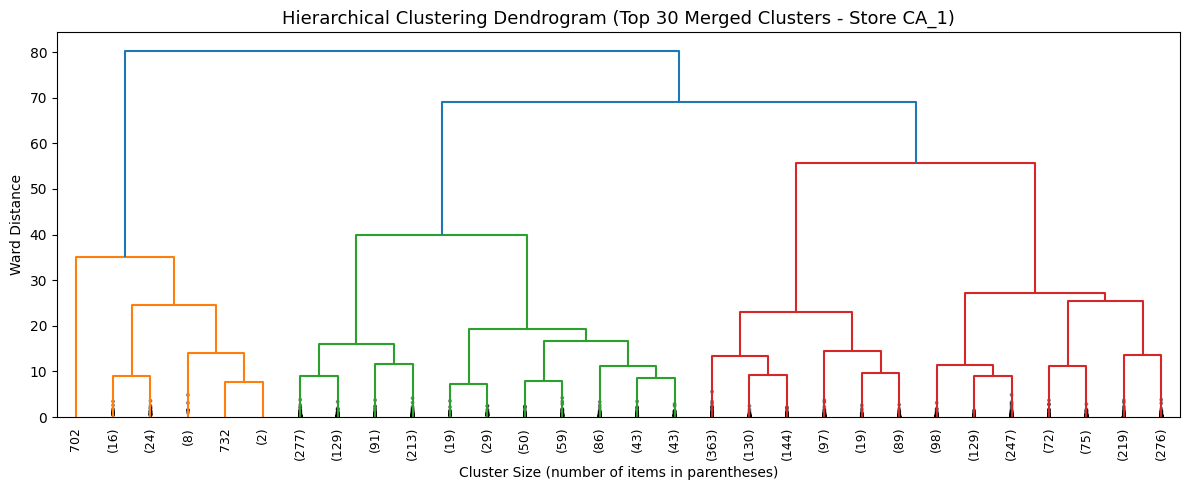


--- Clustering Comparison: K-Means vs Hierarchical ---
K-Means (K=3) Silhouette Score:      0.3464
Hierarchical (K=3) Silhouette Score: 0.3057

Cross-Tabulation (Rows = K-Means Groups, Columns = Hierarchical Clusters):
hier_cluster     1     2     3   All
group                               
Fast Sellers    52     9     0    61
Medium Sellers   0   884   194  1078
Slow Sellers     0   146  1764  1910
All             52  1039  1958  3049

Decision: Keeping K-Means as the final item grouping method.


In [ ]:
# Import hierarchical clustering tools from scipy
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

print("Running Hierarchical Clustering (Ward linkage) on scaled training item features...")

# 1. Compute the linkage matrix using Ward's method
# Ward's method merges clusters that cause the smallest increase in variance
linkage_matrix = linkage(X_items_scaled, method="ward")

# 2. Plot a clean, readable dendrogram (truncated to the last 30 merges)
# Showing all 3,049 individual items would make the x-axis unreadable
plt.figure(figsize=(12, 5))
dendrogram(
    linkage_matrix,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=9,
    show_contracted=True
)
plt.title("Hierarchical Clustering Dendrogram (Top 30 Merged Clusters - Store CA_1)", fontsize=13)
plt.xlabel("Cluster Size (number of items in parentheses)")
plt.ylabel("Ward Distance")
plt.tight_layout()
plt.show()

# 3. Cut the dendrogram into the same number of clusters as K-Means (K = 3)
hier_labels = fcluster(linkage_matrix, t=best_k, criterion="maxclust")
item_features["hier_cluster"] = hier_labels

# 4. Compare Silhouette Scores
hier_sil = silhouette_score(X_items_scaled, hier_labels)
kmeans_sil = silhouette_scores[best_k]

print("\n--- Clustering Comparison: K-Means vs Hierarchical ---")
print(f"K-Means (K={best_k}) Silhouette Score:      {kmeans_sil:.4f}")
print(f"Hierarchical (K={best_k}) Silhouette Score: {hier_sil:.4f}")

# 5. Cross-tabulation table to see how K-Means groups overlap with Hierarchical clusters
print("\nCross-Tabulation (Rows = K-Means Groups, Columns = Hierarchical Clusters):")
comparison_table = pd.crosstab(
    item_features["group"],
    item_features["hier_cluster"],
    margins=True
)
print(comparison_table)

print("\nDecision: Keeping K-Means as the final item grouping method.")

## Step 10: Assign Possible Anomaly Reasons (Priority-Based)

### What we are doing in this cell
We are assigning a human-readable **reason** to every flagged anomaly in the validation dataset using this exact priority order:
1. **Price change** (`price_change != 0`)
2. **Event** (`has_event == 1`)
3. **SNAP day** (`snap == 1`)
4. **Unexplained** (if none of the above apply)

Normal (non-anomaly) days will be labeled as `"None"`.

### Why we need this step
Showing a store manager "Anomaly on 2016-04-04" is helpful, but giving them a quick context hint—like "Price change" or "SNAP day"—makes the DemandLens dashboard immediately actionable.

### What problem this step solves
It adds business context to every anomaly alert. **Important:** These reasons are *possible hints* based on calendar and pricing data, not proven causes.

### What output we should expect
A summary count and percentage breakdown of each anomaly reason among all flagged anomalies, plus a preview of 10 flagged rows showing their assigned reasons.

In [ ]:
# Define a reusable function to assign anomaly reasons using our exact priority order
def assign_anomaly_reasons(df):
    """
    Assigns a possible reason to each flagged anomaly based on priority:
    1. Price change
    2. Event
    3. SNAP day
    4. Unexplained
    Normal (non-anomaly) rows are labeled 'None'.
    """
    conditions = [
        ~df["is_anomaly"],          # Not an anomaly
        df["price_change"] != 0,    # Priority 1: Price change
        df["has_event"] == 1,       # Priority 2: Event
        df["snap"] == 1             # Priority 3: SNAP day
    ]

    choices = [
        "None",
        "Price change",
        "Event",
        "SNAP day"
    ]

    # If a row is an anomaly and none of the 3 conditions match, label it 'Unexplained'
    return np.select(conditions, choices, default="Unexplained")

# Apply the function to the validation dataset
val_df["reason"] = assign_anomaly_reasons(val_df)

# Filter only the flagged anomalies to inspect the reason breakdown
anomalies_only = val_df[val_df["is_anomaly"]]

print("--- Anomaly Reason Breakdown (Validation Data) ---")
print(f"Total Flagged Anomalies: {len(anomalies_only):,}\n")

reason_counts = anomalies_only["reason"].value_counts()
for reason_name, count in reason_counts.items():
    pct = (count / len(anomalies_only)) * 100
    print(f" - {reason_name:<15}: {count:>5,} ({pct:.2f}%)")

print("\nNote: These reasons are possible hints for review, not proven causes.")

# Show a sample of 10 flagged anomalies with their assigned reasons
print("\nSample Flagged Anomalies with Reasons:")
display_cols = ["item_id", "date", "sales", "forecast", "residual", "direction", "group", "flagged_by", "reason"]
print(anomalies_only[display_cols].head(10))

--- Anomaly Reason Breakdown (Validation Data) ---
Total Flagged Anomalies: 2,018

 - Unexplained    : 1,121 (55.55%)
 - SNAP day       :   888 (44.00%)
 - Price change   :     9 (0.45%)

Note: These reasons are possible hints for review, not proven causes.

Sample Flagged Anomalies with Reasons:
         item_id       date  sales   forecast   residual direction  \
7    FOODS_1_001 2016-04-04      4   0.923384   3.076616     spike   
21   FOODS_1_001 2016-04-18      4   0.885024   3.114976     spike   
56   FOODS_1_003 2016-03-28      4   0.740433   3.259567     spike   
254  FOODS_1_011 2016-03-30      4   0.153791   3.846209     spike   
447  FOODS_1_017 2016-04-24      4   0.917930   3.082070     spike   
453  FOODS_1_018 2016-04-02     16  16.979145  -0.979145      drop   
454  FOODS_1_018 2016-04-03     16  15.012317   0.987683     spike   
458  FOODS_1_018 2016-04-07      2  12.417914 -10.417914      drop   
460  FOODS_1_018 2016-04-09      5  13.641409  -8.641409      drop   
47

## Step 11: Visualizations — Daily Anomalies, Reasons, and Silhouette Scores

### What we are doing in this cell
We are creating three clean, readable summary charts:
1. **Anomalies per Day:** Shows how many items were flagged on each day of the validation period.
2. **Anomaly Reasons Bar Chart:** Shows the breakdown of possible reasons (`Unexplained`, `SNAP day`, `Price change`, `Event`).
3. **K-Means Silhouette Score Comparison:** Compares clustering quality for `K = 3, 4, 5`.

*(Note: Our Hierarchical Clustering dendrogram was already plotted in Step 9, and we will plot the 3 sample item sales charts in Step 12.)*

### Why we need this step
Numbers in tables are useful, but visual charts make patterns jump out immediately—for example, seeing if anomalies cluster around the first 10 days of the month (when SNAP benefits are issued in California).

### What problem this step solves
It transforms raw anomaly counts into clear visual insights that can be shared in project reports, presentations, and the DemandLens dashboard.

### What output we should expect
Three cleanly labeled charts displayed one after another: a daily anomaly count chart, a reason breakdown bar chart, and a K-Means silhouette score comparison chart.

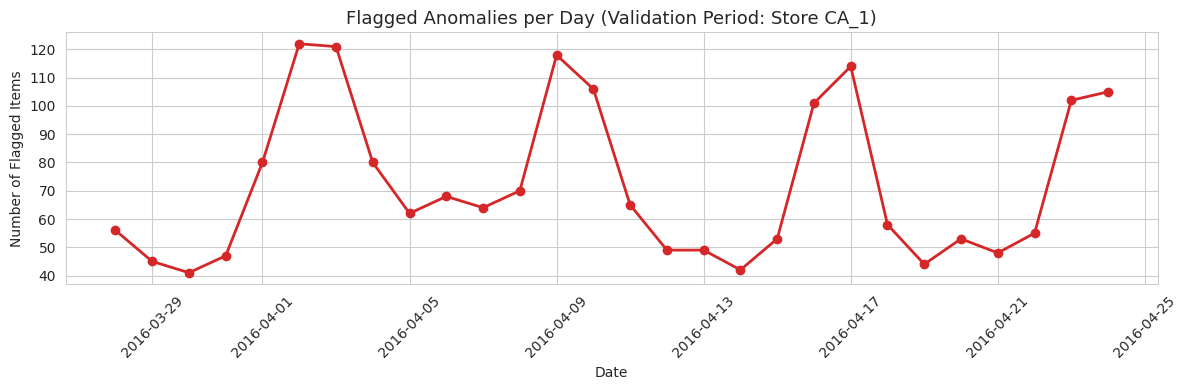

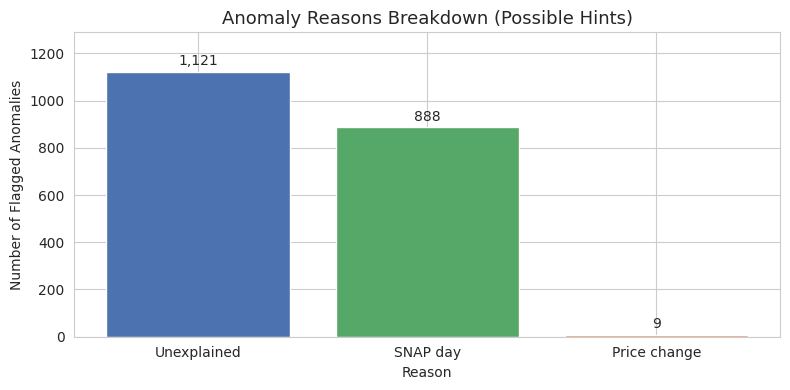

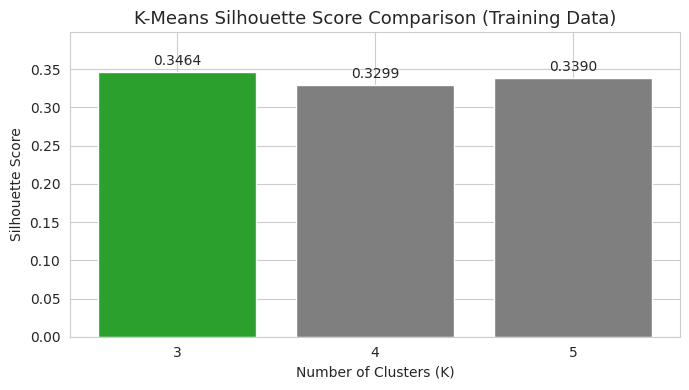

In [ ]:
# Set a clean visual style for all charts
sns.set_style("whitegrid")

# ---------------------------------------------------------
# Chart 1: Anomalies per Day (Validation Period)
# ---------------------------------------------------------
anomalies_per_day = (
    val_df[val_df["is_anomaly"]]
    .groupby("date")
    .size()
)

plt.figure(figsize=(12, 4))
plt.plot(anomalies_per_day.index, anomalies_per_day.values, marker="o", color="#d62728", linewidth=2)
plt.title("Flagged Anomalies per Day (Validation Period: Store CA_1)", fontsize=13)
plt.xlabel("Date")
plt.ylabel("Number of Flagged Items")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Chart 2: Anomaly Reasons Bar Chart
# ---------------------------------------------------------
reason_counts = val_df[val_df["is_anomaly"]]["reason"].value_counts()

plt.figure(figsize=(8, 4))
bars = plt.bar(reason_counts.index, reason_counts.values, color=["#4c72b0", "#55a868", "#dd8452", "#c44e52"][:len(reason_counts)])
plt.title("Anomaly Reasons Breakdown (Possible Hints)", fontsize=13)
plt.xlabel("Reason")
plt.ylabel("Number of Flagged Anomalies")

# Add exact count labels on top of each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 15,
        f"{int(height):,}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.ylim(0, reason_counts.max() * 1.15)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Chart 3: K-Means Silhouette Score Comparison (K = 3, 4, 5)
# ---------------------------------------------------------
k_list = list(silhouette_scores.keys())
score_list = list(silhouette_scores.values())

plt.figure(figsize=(7, 4))
bars_k = plt.bar([str(k) for k in k_list], score_list, color=["#2ca02c" if k == best_k else "#7f7f7f" for k in k_list])
plt.title("K-Means Silhouette Score Comparison (Training Data)", fontsize=13)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")

# Add exact score labels on top of each bar
for bar in bars_k:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.005,
        f"{height:.4f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.ylim(0, max(score_list) * 1.15)
plt.tight_layout()
plt.show()

## Step 12: Visualizations — Three Sample Item Sales Charts with Anomalies

### What we are doing in this cell
We are selecting **three sample items**—one from **Fast Sellers**, one from **Medium Sellers**, and one from **Slow Sellers**—and plotting their daily actual sales against the 7-day LightGBM forecast across the validation period. Any day flagged as an anomaly is highlighted with a **red dot**.

### Why we need this step
Looking at individual item timelines helps us visually verify that our anomaly detection makes real-world sense. We can immediately see whether the red dots land on true spikes and sudden drops.

### What problem this step solves
It acts as a visual sanity check for our group-specific thresholds and Isolation Forest flags before we export our final files for the DemandLens dashboard.

### What output we should expect
Three clean time-series charts (one per item group), each showing the blue actual sales line, the dashed orange forecast line, and red circles marking the flagged anomaly days.

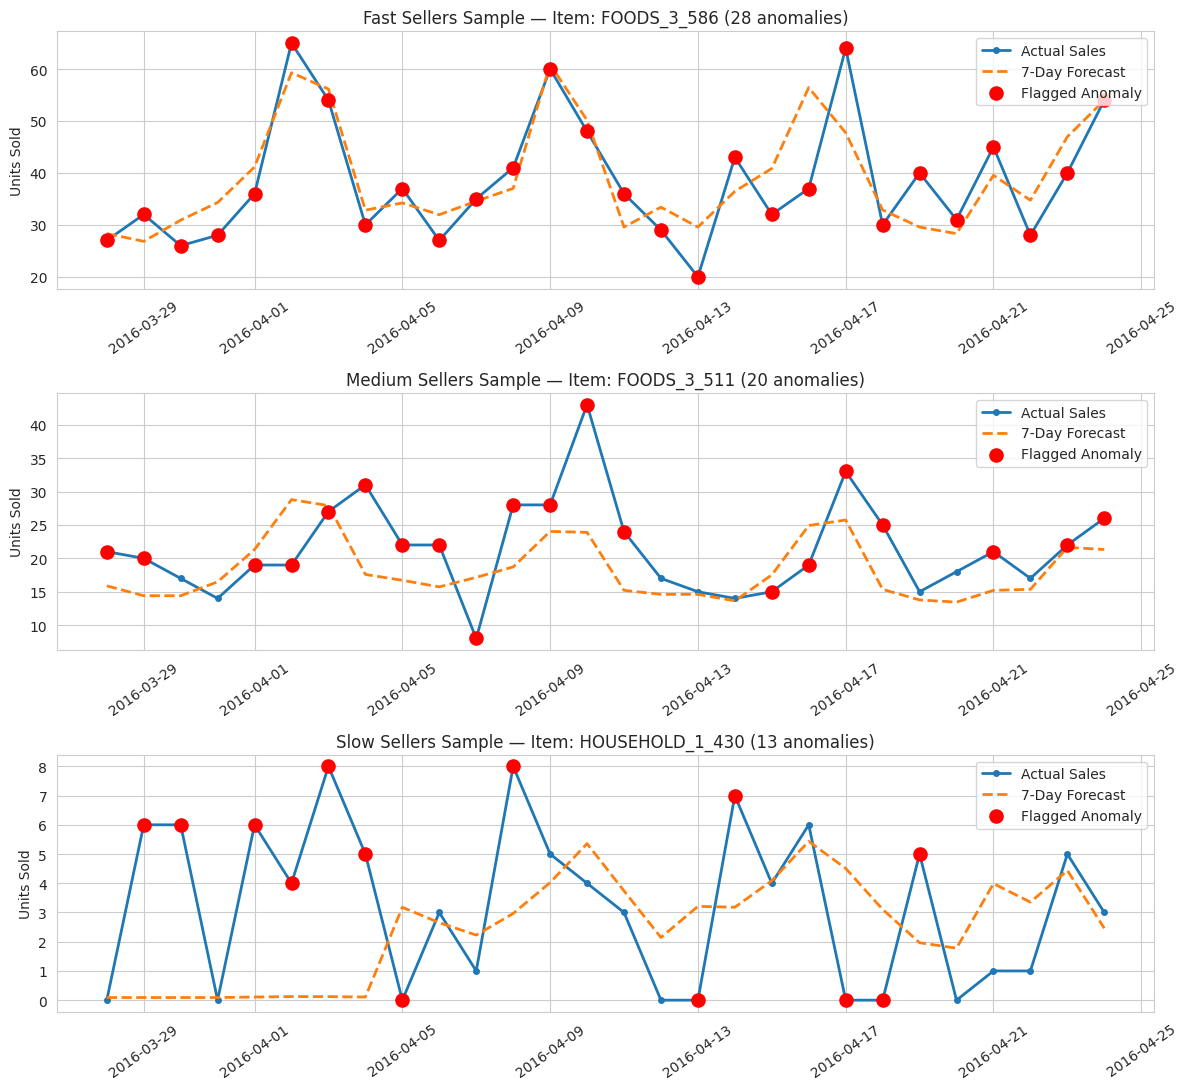

In [ ]:
# Select one sample item with anomalies from each of the 3 item groups
sample_items = []

for group_name in ["Fast Sellers", "Medium Sellers", "Slow Sellers"]:
    # Find anomalies belonging to this group
    group_anoms = val_df[(val_df["group"] == group_name) & (val_df["is_anomaly"])]

    if len(group_anoms) > 0:
        # Pick the item with the most flagged anomaly days in this group
        top_item = group_anoms["item_id"].value_counts().index[0]
        sample_items.append((group_name, top_item))

# Create 3 stacked subplots (one for each sample item)
fig, axes = plt.subplots(len(sample_items), 1, figsize=(12, 11), sharex=False)

for idx, (group_name, item_id) in enumerate(sample_items):
    ax = axes[idx]

    # Filter validation data for this specific item and sort by date
    item_data = val_df[val_df["item_id"] == item_id].sort_values("date")
    item_anomalies = item_data[item_data["is_anomaly"]]

    # Plot Actual Sales (solid blue line)
    ax.plot(
        item_data["date"],
        item_data["sales"],
        label="Actual Sales",
        color="#1f77b4",
        linewidth=2,
        marker="o",
        markersize=4
    )

    # Plot 7-Day Forecast (dashed orange line)
    ax.plot(
        item_data["date"],
        item_data["forecast"],
        label="7-Day Forecast",
        color="#ff7f0e",
        linestyle="--",
        linewidth=2
    )

    # Highlight Flagged Anomaly Points in Red
    ax.scatter(
        item_anomalies["date"],
        item_anomalies["sales"],
        color="red",
        s=90,
        zorder=5,
        label="Flagged Anomaly"
    )

    # Format titles and labels
    ax.set_title(f"{group_name} Sample — Item: {item_id} ({len(item_anomalies)} anomalies)", fontsize=12)
    ax.set_ylabel("Units Sold")
    ax.legend(loc="upper right")
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

## Step 13: Export Validation Results and Trained Models to Google Drive

### What we are doing in this cell
We are mounting Google Drive, creating our DemandLens backend handover folder (if it does not already exist), and saving all required validation outputs and models:
1. `anomalies_validation.parquet` (containing the exact 10 required columns)
2. `item_groups.csv` (mapping every item to its K-Means group)
3. `group_thresholds.csv` (saving each group's anomaly threshold)
4. `kmeans_model.joblib` (and `kmeans_scaler.joblib` for scaling new items)
5. `isolation_forest_model.joblib`

*(Note: `anomalies_test.parquet` will be created and exported in Step 14 after our final test evaluation.)*

### Why we need this step
Google Colab's local storage (`/content/`) is temporary and gets deleted when the session ends. Saving everything to Google Drive ensures our backend and dashboard team have permanent, ready-to-use files.

### What problem this step solves
It prevents losing our trained clustering/anomaly models and ensures the exported `anomalies_validation.parquet` file matches the exact 10-column schema required by the DemandLens backend.

### What output we should expect
A Google Drive mount confirmation, followed by `[SAVED]` messages with the file size (in KB/MB) for each exported file.

In [ ]:

# 1. Create a folder in Google Colab Files panel
HANDOVER_DIR = "/content/backend_handover"
os.makedirs(HANDOVER_DIR, exist_ok=True)

print(f"Saving outputs to: {HANDOVER_DIR}\n")

# 2. Prepare anomalies_validation.parquet with EXACT 10 columns
required_output_cols = [
    "item_id",
    "date",
    "sales",
    "forecast",
    "residual",
    "direction",
    "group",
    "is_anomaly",
    "flagged_by",
    "reason"
]

anomalies_val_export = val_df[required_output_cols].copy()

val_export_path = os.path.join(
    HANDOVER_DIR, "anomalies_validation.parquet"
)
anomalies_val_export.to_parquet(val_export_path, index=False)

# 3. Export item_groups.csv
item_groups_cols = [
    "item_id",
    "avg_sales",
    "zero_sales_share",
    "sales_std",
    "weekend_sales_ratio",
    "group"
]

item_groups_path = os.path.join(HANDOVER_DIR, "item_groups.csv")
item_features[item_groups_cols].to_csv(item_groups_path, index=False)

# 4. Export group_thresholds.csv
thresholds_path = os.path.join(HANDOVER_DIR, "group_thresholds.csv")
group_thresholds.to_csv(thresholds_path, index=False)

# 5. Export K-Means model and StandardScaler
kmeans_path = os.path.join(HANDOVER_DIR, "kmeans_model.joblib")
scaler_path = os.path.join(HANDOVER_DIR, "kmeans_scaler.joblib")

joblib.dump(kmeans_model, kmeans_path)
joblib.dump(scaler, scaler_path)

# 6. Export Isolation Forest model
iso_path = os.path.join(HANDOVER_DIR, "isolation_forest_model.joblib")
joblib.dump(iso_model, iso_path)

# 7. Verify all saved files
saved_files = [
    val_export_path,
    item_groups_path,
    thresholds_path,
    kmeans_path,
    scaler_path,
    iso_path
]

print("--- Export Verification ---")

for filepath in saved_files:
    size_kb = os.path.getsize(filepath) / 1024
    print(f"[SAVED] {os.path.basename(filepath):<32} ({size_kb:,.1f} KB)")

print("\n--- Exported Columns ---")
print(list(anomalies_val_export.columns))

print("\n--- All Files ---")
print(os.listdir(HANDOVER_DIR))


Saving outputs to: /content/backend_handover

--- Export Verification ---
[SAVED] anomalies_validation.parquet     (1,604.2 KB)
[SAVED] item_groups.csv                  (307.7 KB)
[SAVED] group_thresholds.csv             (0.3 KB)
[SAVED] kmeans_model.joblib              (12.7 KB)
[SAVED] kmeans_scaler.joblib             (1.0 KB)
[SAVED] isolation_forest_model.joblib    (998.7 KB)

--- Exported Columns ---
['item_id', 'date', 'sales', 'forecast', 'residual', 'direction', 'group', 'is_anomaly', 'flagged_by', 'reason']

--- All Files ---
['isolation_forest_model.joblib', 'kmeans_scaler.joblib', 'kmeans_model.joblib', 'group_thresholds.csv', 'item_groups.csv', 'anomalies_validation.parquet']
